# PatchPriority: Machine Learning for Exploitation-Likelihood Prediction & Risk-Based Vulnerability Triage

**Course:** Machine Learning Cloud Services
**Project:** PatchPriority — Predicting Which Vulnerabilities Attackers Actually Use
**Dataset:** NVD CVE CVSS KEV EPSS Vulnerabilities 2020–2026 (201,542 CVE records)

A security team can patch a few hundred vulnerabilities per sprint, out of tens of thousands open. The default policy — *patch Critical, then High* — ranks by how bad a bug would be if exploited, not by how likely it is to be exploited. This notebook asks whether **information available on the day a CVE is published** can rank vulnerabilities by real-world exploitation (CISA KEV membership).

| Technique | Question |
|---|---|
| Linear regression | How much of the CVSS score is redundant / recoverable from text? |
| Decision tree | Can we write an auditable triage rule set? |
| Random forest | Which publication-day signals drive exploitation? |
| Logistic regression (text + metadata) | Best ranking model — deployed by `patchpriority.service` |
| K-Means | Do vulnerabilities form archetypes with very different exploitation rates? |

**Methodological ground rules**
1. `Rejected` CVEs dropped.
2. **No leakage:** only publication-day fields are features (`patchpriority.features.FEATURES`). Section 2 shows why `vuln_status`, CPE/reference/weakness counts and NVD/CISA-assigned CWEs are excluded.
3. **EPSS is a competitor, never a feature.** Its scores date from May 2026 and use observed exploitation activity, so it is an upper bound, not a like-for-like baseline.
4. **Positive-unlabelled target:** a CVE not (yet) in KEV is unlabelled, not safe. Recent CVEs have had less time to be listed, so test precision is a lower bound.
5. **Temporal split:** train 2020–2023, validation 2024, test 2025–2026.

## 1. Setup

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path('src').resolve()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import patchpriority
from patchpriority.data import load_and_preprocess_dataset
from patchpriority.features import FEATURES
from patchpriority.metrics import benchmark_standard_policies, ranking_metrics, DEFAULT_KS
from patchpriority.models.regression import train_cvss_redundancy_model, train_cvss_text_recovery_model
from patchpriority.models.decision_tree import train_decision_tree_triage
from patchpriority.models.random_forest import train_random_forest_ranker
from patchpriority.models.logistic import train_logistic_ranker
from patchpriority.models.clustering import discover_vulnerability_archetypes

pd.set_option('display.max_colwidth', 80)
plt.style.use('seaborn-v0_8-whitegrid')
print(f"PatchPriority v{patchpriority.__version__}")

PatchPriority v0.1.0


## 2. Ingestion, Leakage Audit & Temporal Split

The loader drops `Rejected` CVEs and the KEV-contaminated `mentions_*` / `kev_*` columns, recomputes keyword flags from `description_en`, takes the CWE supplied by the CNA (not NVD or CISA-ADP), and harmonises CVSS v3.1/v4.0 base metrics.

In [2]:
PARQUET = Path("archive (1)/nvd_cve_records.parquet")
train_df, val_df, test_df = load_and_preprocess_dataset(PARQUET)
all_df = pd.concat([train_df, val_df, test_df])
TARGET = 'kev_is_known_exploited'

for name, d in [('Train 2020-2023', train_df), ('Val 2024', val_df), ('Test 2025-2026', test_df)]:
    print(f"{name:16s} {len(d):7,} CVEs  {d[TARGET].sum():4d} KEV  ({d[TARGET].mean():.3%})")
print(f"\nModel features ({len(FEATURES)}): {FEATURES}")

Train 2020-2023   87,080 CVEs   639 KEV  (0.734%)
Val 2024          39,753 CVEs   159 KEV  (0.400%)
Test 2025-2026    67,646 CVEs   241 KEV  (0.356%)

Model features (17): ['description_en', 'source_identifier', 'cna_cwe', 'cvss_attack_vector', 'cvss_attack_complexity', 'cvss_privileges_required', 'cvss_user_interaction', 'cvss_confidentiality_impact', 'cvss_integrity_impact', 'cvss_availability_impact', 'best_cvss_base_score', 'description_length', 'kw_rce', 'kw_sqli', 'kw_xss', 'kw_exploit', 'kw_overflow']


**Why some tempting columns are excluded.** NVD analyses KEV CVEs first, and CISA adds a catalogue reference when it lists one. Fields filled in by that later analysis therefore encode the label itself:

In [3]:
audit = pd.concat({
    'vuln_status': all_df.groupby('vuln_status')[TARGET].agg(['size', 'mean']),
    'has CPE matches': all_df.groupby(all_df['cpe_match_count'] > 0)[TARGET].agg(['size', 'mean']),
}).rename(columns={'size': 'CVEs', 'mean': 'KEV rate'})
audit['KEV rate'] = (audit['KEV rate'] * 100).round(3).astype(str) + '%'
display(audit)
print("A model given these would learn 'was NVD-analysed', not 'will be exploited'.")

CVEs KEV rate
vuln_status     Analyzed              56526   1.835%
                Awaiting Analysis      1461     0.0%
                Deferred              31379     0.0%
                Modified             104609   0.001%
                Received                 73     0.0%
                Undergoing Analysis     431   0.232%
has CPE matches False                 33324     0.0%
                True                 161155   0.645%

A model given these would learn 'was NVD-analysed', not 'will be exploited'.


## 3. Exploratory Analysis

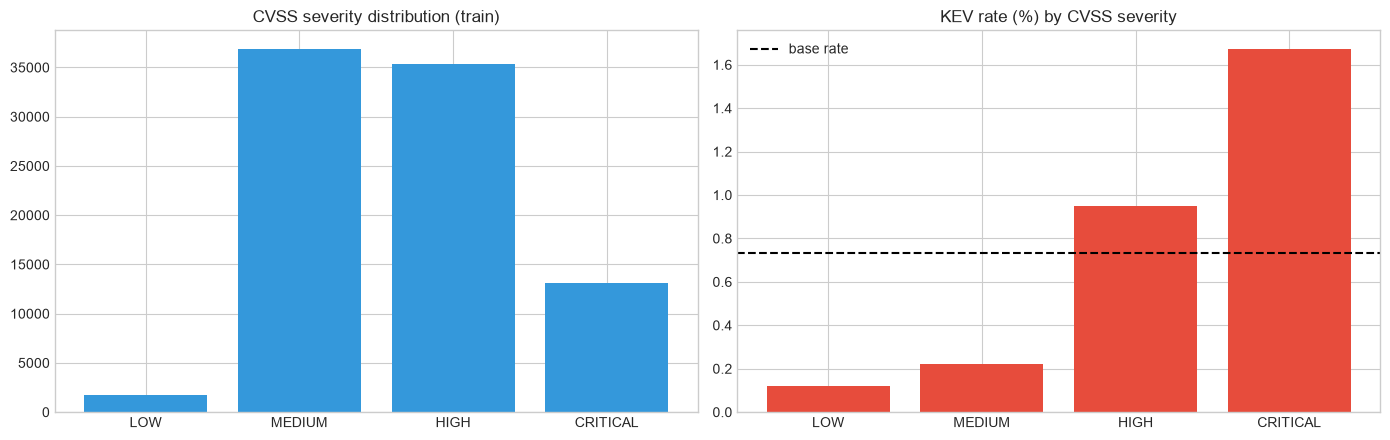

CNA-assigned CWEs with >=200 CVEs, by exploitation lift:


,CVEs,kev_rate,lift
cna_cwe,,,
CWE-94,355,0.036620,5.0
CWE-502,388,0.020619,2.8
CWE-306,260,0.019231,2.6
CWE-78,783,0.017880,2.4
CWE-284,867,0.011534,1.6
CWE-121,601,0.011647,1.6
CWE-79,5902,0.000508,0.1
CWE-476,450,0.000000,0.0
CWE-601,265,0.000000,0.0


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sev = ['LOW', 'MEDIUM', 'HIGH', 'CRITICAL']
counts = train_df['best_cvss_base_severity'].value_counts().reindex(sev)
axes[0].bar(sev, counts.values, color='#3498db')
axes[0].set_title('CVSS severity distribution (train)')
rate = train_df.groupby('best_cvss_base_severity')[TARGET].mean().reindex(sev) * 100
axes[1].bar(sev, rate.values, color='#e74c3c')
axes[1].axhline(train_df[TARGET].mean() * 100, color='black', ls='--', label='base rate')
axes[1].set_title('KEV rate (%) by CVSS severity'); axes[1].legend()
plt.tight_layout(); plt.show()

cwe = train_df[train_df['cna_cwe'] != 'NONE'].groupby('cna_cwe')[TARGET].agg(CVEs='size', kev_rate='mean')
cwe['lift'] = (cwe['kev_rate'] / train_df[TARGET].mean()).round(1)
print("CNA-assigned CWEs with >=200 CVEs, by exploitation lift:")
display(cwe[cwe['CVEs'] >= 200].sort_values('lift', ascending=False).iloc[np.r_[0:6, -4:0]])

## 4. Baseline Policies (test split 2025–2026)

Fixed-threshold policies, plus EPSS as a ranking. The proposal's budget of k = 2,751 was the size of the EPSS `very_high` bucket on the *whole* dataset; the test split has only ~240 positives, so the equal-effort budget here is the test-split bucket size (k = 224).

In [5]:
baselines = benchmark_standard_policies(test_df)
display(baselines.round({'precision': 4, 'recall': 4, 'f1': 3}))
y_test = test_df[TARGET].values.astype(int)
epss_metrics = ranking_metrics(y_test, test_df['epss_score'].fillna(0).values)

,Policy,patches_required,kev_caught,precision,recall,f1
0,CVSS HIGH + CRITICAL,28812,213,0.0074,0.8838,0.015
1,CVSS CRITICAL only,6030,99,0.0164,0.4108,0.032
2,EPSS very_high bucket,224,82,0.3661,0.3402,0.353
3,EPSS top 1%,86,45,0.5233,0.1867,0.275


## 5. Technique 1 — Linear Regression

- **Model A:** CVSS base score from its two sub-scores. A near-perfect R² shows the score adds no information beyond its inputs.
- **Model B:** Score from description TF-IDF alone (Ridge). Large residuals flag CVEs whose rating disagrees with their description.

Model B's R² decays with distance from the training years, partly because CVSS v4.0 (absent before 2024) rescored much of 2025–26. A deployed severity model would need regular retraining.

In [6]:
lr_a, r2_a = train_cvss_redundancy_model(train_df, test_df)
ridge, text_metrics, residuals = train_cvss_text_recovery_model(train_df, test_df, max_features=2000)
print(f"Model A (sub-scores)  test R² = {r2_a:.4f}")
_, val_text_metrics, _ = train_cvss_text_recovery_model(train_df, val_df, max_features=2000)
print(f"Model B (text only)   train R² = {text_metrics['train_r2']:.3f} | 2024 R² = {val_text_metrics['test_r2']:.3f} "
      f"| 2025-26 R² = {text_metrics['test_r2']:.3f} | 2025-26 MAE = {text_metrics['test_mae']:.2f}")
print(f"CVSS v4.0 share: train {(train_df['best_cvss_version'] == '4.0').mean():.0%}, test {(test_df['best_cvss_version'] == '4.0').mean():.0%}")
print("\nLargest disagreements between assigned score and description:")
display(residuals[['cve_id', 'best_cvss_base_score', 'predicted_score', 'description_en']].head(5))

Model A (sub-scores)  test R² = 0.9848


Model B (text only)   train R² = 0.510 | 2024 R² = 0.257 | 2025-26 R² = 0.084 | 2025-26 MAE = 1.24
CVSS v4.0 share: train 0%, test 28%

Largest disagreements between assigned score and description:


,cve_id,best_cvss_base_score,predicted_score,description_en
9217,CVE-2024-14025,0.1,8.492472,An SQL injection vulnerability has been reported to affect Video Station. If...
47742,CVE-2025-49842,1.0,9.107425,conda-forge-webservices is the web app deployed to run conda-forge admin com...
66247,CVE-2020-11936,3.1,11.086584,gdbus setgid privilege escalation
25970,CVE-2025-66479,1.8,9.247427,Anthropic Sandbox Runtime is a lightweight sandboxing tool for enforcing fil...
14083,CVE-2025-48723,0.6,8.043046,A buffer overflow vulnerability has been reported to affect Qsync Central. I...


## 6. Technique 2 — Decision Tree (Auditable Triage Rules)

Cost-sensitive CART (`class_weight='balanced'`) capped at 15 leaves, so the whole policy fits on a page.

In [7]:
dt_pipe, rules, dt_metrics = train_decision_tree_triage(train_df, test_df, max_leaf_nodes=15)
print(f"Patches required: {dt_metrics['patches_required']:,} | KEV caught: {dt_metrics['kev_caught']} "
      f"| precision {dt_metrics['precision']:.2%} | recall {dt_metrics['recall']:.2%} | PR-AUC {dt_metrics['pr_auc']:.4f}")
crit = baselines.set_index('Policy').loc['CVSS CRITICAL only']
print(f"For comparison, CVSS CRITICAL only: {int(crit['patches_required']):,} patches | KEV caught: {int(crit['kev_caught'])} | precision {crit['precision']:.2%}")
print("\n" + rules)

Patches required: 8,769 | KEV caught: 155 | precision 1.77% | recall 64.32% | PR-AUC 0.0178
For comparison, CVSS CRITICAL only: 6,030 patches | KEV caught: 99 | precision 1.64%

|--- cat__cvss_integrity_impact_HIGH <= 0.50
|   |--- cat__source_identifier_secure@microsoft.com <= 0.50
|   |   |--- text__unauthenticated <= 0.10
|   |   |   |--- cat__source_identifier_security@vmware.com <= 0.50
|   |   |   |   |--- cat__cvss_confidentiality_impact_HIGH <= 0.50
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- cat__cvss_confidentiality_impact_HIGH >  0.50
|   |   |   |   |   |--- class: 0
|   |   |   |--- cat__source_identifier_security@vmware.com >  0.50
|   |   |   |   |--- class: 1
|   |   |--- text__unauthenticated >  0.10
|   |   |   |--- class: 0
|   |--- cat__source_identifier_secure@microsoft.com >  0.50
|   |   |--- class: 1
|--- cat__cvss_integrity_impact_HIGH >  0.50
|   |--- text__remote <= 0.10
|   |   |--- cat__source_identifier_secure@microsoft.com <= 0.50
|   |   |   |

## 7. Technique 3 — Random Forest (Exploitation Drivers)

Random Forest test PR-AUC: 0.0599


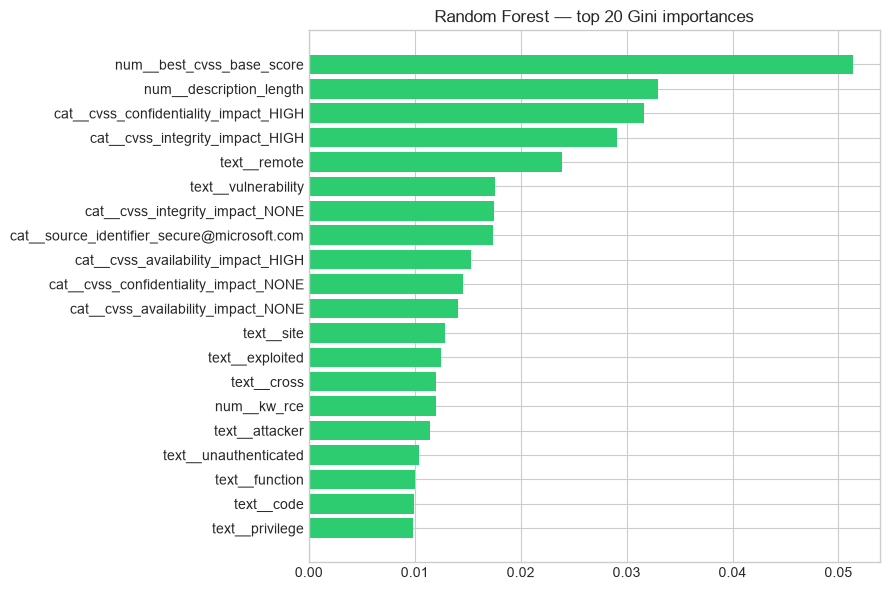

In [8]:
rf_pipe, rf_metrics, rf_importance = train_random_forest_ranker(train_df, test_df)
print(f"Random Forest test PR-AUC: {rf_metrics['pr_auc']:.4f}")
top = rf_importance.head(20)[::-1]
plt.figure(figsize=(9, 6))
plt.barh(top['feature'], top['importance'], color='#2ecc71')
plt.title('Random Forest — top 20 Gini importances'); plt.tight_layout(); plt.show()

## 8. Production Ranker — Logistic Regression over Text + Metadata

Sparse logistic regression over description uni/bi-grams plus one-hot CNA, CWE and CVSS metrics. This is the model `python -m patchpriority.service` trains and serves. Validation (2024) and test (2025–26) are both reported to show the result is not a one-split fluke.

In [9]:
lr_pipe, lr_metrics, lr_coefs = train_logistic_ranker(train_df, test_df)
_, lr_val_metrics, _ = train_logistic_ranker(train_df, val_df)
print(f"PR-AUC  validation 2024: {lr_val_metrics['pr_auc']:.4f} ({lr_val_metrics['pr_auc']/lr_val_metrics['base_rate']:.0f}x base rate)")
print(f"PR-AUC  test 2025-2026: {lr_metrics['pr_auc']:.4f} ({lr_metrics['pr_auc']/lr_metrics['base_rate']:.0f}x base rate)")
print("\nStrongest signals of exploitation:")
display(lr_coefs.head(15))
print("Strongest signals against:")
display(lr_coefs.tail(10))

PR-AUC  validation 2024: 0.1348 (34x base rate)
PR-AUC  test 2025-2026: 0.0874 (25x base rate)

Strongest signals of exploitation:


,feature,coef
3537,text__aware,3.917241
14954,text__roundcube,3.535985
2785,text__apple aware,3.486559
3538,text__aware report,3.361996
14591,text__report issue,3.353229
9802,text__issue actively,3.113765
2061,text__actively exploited,3.052822
2784,text__apple,3.003757
19971,text__zimbra,2.862452
2060,text__actively,2.831126


Strongest signals against:


,feature,coef
20074,cat__source_identifier_psirt@huawei.com,-1.468631
20113,cat__source_identifier_security@huntr.dev,-1.503210
20085,cat__source_identifier_report@snyk.io,-1.699891
20099,cat__source_identifier_security-alert@hpe.com,-1.705816
20062,cat__source_identifier_productcert@siemens.com,-1.800362
20015,cat__source_identifier_contact@wpscan.com,-1.811824
20013,cat__source_identifier_cna@vuldb.com,-1.816901
2542,text__allows attacker,-1.830305
20322,cat__cvss_attack_vector_PHYSICAL,-1.988954
8149,text__function,-2.103549


## 9. Model Comparison at Fixed Patch Budgets (test split)

,PR-AUC,P@100,P@224,P@500,P@1000,R@100,R@224,R@500,R@1000
CVSS score,0.0158,0.04,0.0402,0.038,0.031,0.0166,0.0373,0.0788,0.1286
Decision tree,0.0178,0.04,0.0312,0.040,0.031,0.0166,0.0290,0.0830,0.1286
Random forest,0.0599,0.11,0.0759,0.090,0.072,0.0456,0.0705,0.1867,0.2988
Logistic (text+meta),0.0874,0.19,0.1339,0.104,0.087,0.0788,0.1245,0.2158,0.3610
"EPSS (hindsight, upper bound)",0.3225,0.48,0.3661,0.260,0.164,0.1992,0.3402,0.5394,0.6805


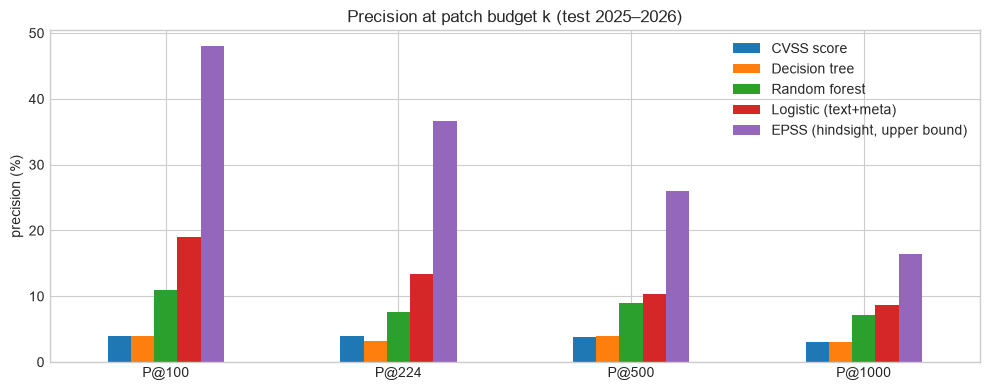

In [10]:
rankers = {'Decision tree': dt_metrics, 'Random forest': rf_metrics,
           'Logistic (text+meta)': lr_metrics, 'EPSS (hindsight, upper bound)': epss_metrics}
cvss = test_df['best_cvss_base_score'].fillna(0).values
rankers = {'CVSS score': ranking_metrics(y_test, cvss), **rankers}

comparison = pd.DataFrame({
    name: {'PR-AUC': m['pr_auc'], **{f'P@{k}': m[f'precision@{k}'] for k in DEFAULT_KS},
           **{f'R@{k}': m[f'recall@{k}'] for k in DEFAULT_KS}}
    for name, m in rankers.items()
}).T
display(comparison.round(4))

ax = comparison[[f'P@{k}' for k in DEFAULT_KS]].mul(100).T.plot(kind='bar', figsize=(10, 4), rot=0)
ax.set_ylabel('precision (%)'); ax.set_title('Precision at patch budget k (test 2025–2026)')
plt.tight_layout(); plt.show()

## 10. Technique 4 — K-Means Vulnerability Archetypes

Descriptions → TF-IDF → TruncatedSVD → MiniBatchKMeans (k = 30), labels withheld; KEV rate measured per cluster afterwards.

,cluster,cve_count,kev_count,kev_rate,lift,top_terms
3,3,1425,60,4.21,5.74,"elevation, privilege, windows, vulnerability, microsoft"
1,1,1697,61,3.59,4.90,"macos, sonoma, 17, issue, addressed"
12,12,1252,43,3.43,4.68,"severity, chromium, chrome, google, security"
5,5,5181,100,1.93,2.63,"code, arbitrary, execution, v9, remote"
17,17,1840,20,1.09,1.48,"device, attacker, exploit, allow, cisco"
16,16,6961,70,1.01,1.37,"information, vulnerability, products, leak, sensitive"
18,18,1529,13,0.85,1.16,"oracle, cvss, access, attacks, vulnerability"
4,4,1433,12,0.84,1.14,"earlier, adobe, requires, victim, interaction"
9,9,25947,183,0.71,0.96,"issue, affects, vulnerability, untrusted, dangerous"
26,26,587,4,0.68,0.93,"snapdragon, iot, mobile, connectivity, auto"


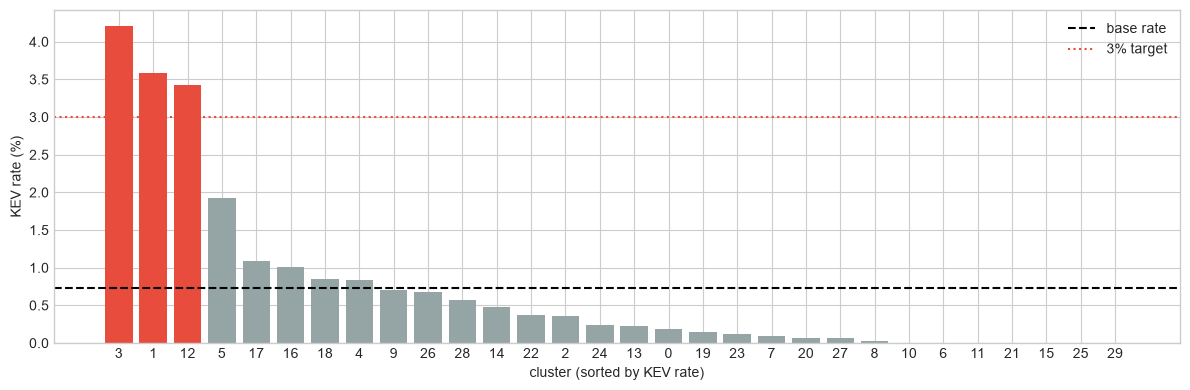

In [11]:
clustered, archetypes = discover_vulnerability_archetypes(train_df)
display(archetypes.head(10))
base = train_df[TARGET].mean() * 100
plt.figure(figsize=(12, 4))
plt.bar(archetypes['cluster'].astype(str), archetypes['kev_rate'],
        color=['#e74c3c' if r > 3 else '#95a5a6' for r in archetypes['kev_rate']])
plt.axhline(base, color='black', ls='--', label='base rate'); plt.axhline(3, color='#e74c3c', ls=':', label='3% target')
plt.xlabel('cluster (sorted by KEV rate)'); plt.ylabel('KEV rate (%)'); plt.legend(); plt.tight_layout(); plt.show()

## 11. Results Against the Proposal's Success Criteria

In [12]:
hi = archetypes[archetypes['kev_rate'] > 3]
k = 224
summary = pd.DataFrame([
    ('CVSS reconstruction R² > 0.95', f"R² = {r2_a:.4f}", r2_a > 0.95),
    ('Decision tree PR-AUC >= 10x no-skill', f"{dt_metrics['pr_auc']/dt_metrics['base_rate']:.1f}x", dt_metrics['pr_auc'] >= 10 * dt_metrics['base_rate']),
    ('Best ranker PR-AUC >= 10x no-skill', f"{lr_metrics['pr_auc']/lr_metrics['base_rate']:.1f}x", lr_metrics['pr_auc'] >= 10 * lr_metrics['base_rate']),
    (f'Best ranker beats CVSS at k={k}', f"{lr_metrics[f'precision@{k}']:.1%} vs {rankers['CVSS score'][f'precision@{k}']:.1%}",
     lr_metrics[f'precision@{k}'] > rankers['CVSS score'][f'precision@{k}']),
    (f'Best ranker beats EPSS at k={k}', f"{lr_metrics[f'precision@{k}']:.1%} vs {epss_metrics[f'precision@{k}']:.1%}",
     lr_metrics[f'precision@{k}'] > epss_metrics[f'precision@{k}']),
    ('>= 2 archetypes with KEV rate > 3%', f"{len(hi)} clusters: " + ' | '.join(hi['top_terms'].str.split(', ').str[:3].str.join(' ')), len(hi) >= 2),
], columns=['criterion', 'result', 'met'])
display(summary)

,criterion,result,met
0,CVSS reconstruction R² > 0.95,R² = 0.9848,True
1,Decision tree PR-AUC >= 10x no-skill,5.0x,False
2,Best ranker PR-AUC >= 10x no-skill,24.5x,True
3,Best ranker beats CVSS at k=224,13.4% vs 4.0%,True
4,Best ranker beats EPSS at k=224,13.4% vs 36.6%,False
5,>= 2 archetypes with KEV rate > 3%,3 clusters: elevation privilege windows | macos sonoma 17 | severity chromiu...,True


### Operational Triage Confusion Matrices (Test Split 2025–2026)

Comparing triage outcomes across three distinct operating postures on the 2025–2026 test set:
1. **CVSS CRITICAL Only (Baseline):** Conventional severity-based triage.
2. **Decision Tree Triage (CART Rules):** Cost-sensitive rule set for auditable triage.
3. **Logistic Ranker @ Budget k=224 (Production Ranker):** Publication-day text + metadata ranking at equal patch capacity.

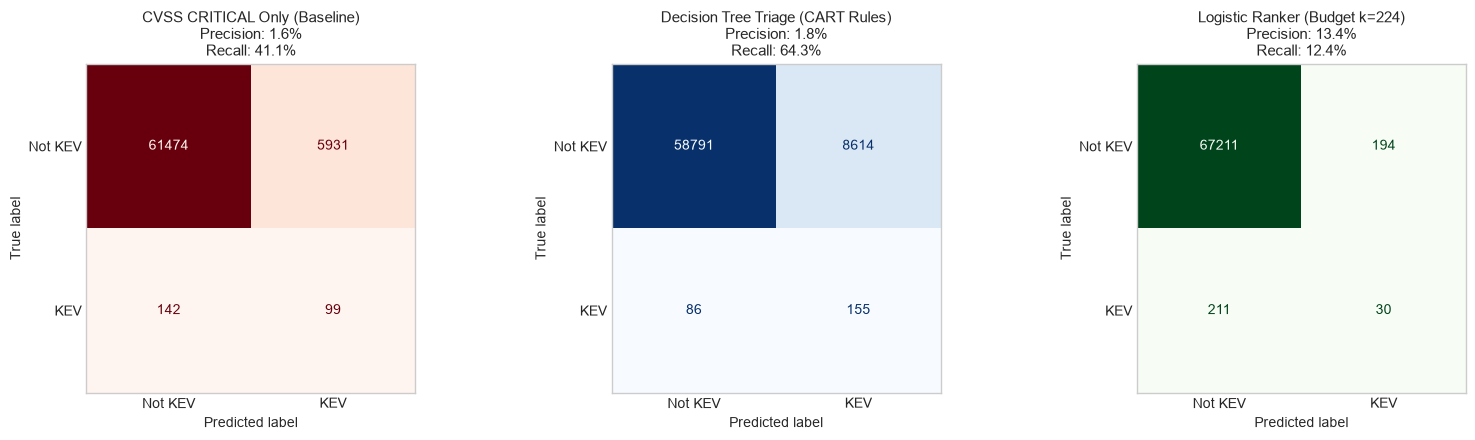

,Policy,True Positives (KEV caught),False Positives (Wasted effort),False Negatives (Missed exploits),True Negatives (Correctly deferred),Precision,Recall
0,CVSS CRITICAL Only,99,5931,142,61474,0.0164,0.4108
1,Decision Tree (Auditable),155,8614,86,58791,0.0177,0.6432
2,Logistic Ranker (Top 224),30,194,211,67211,0.1339,0.1245


In [13]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 1. Baseline: CVSS CRITICAL only
y_pred_crit = (test_df['best_cvss_base_severity'] == 'CRITICAL').values.astype(int)
cm_crit = confusion_matrix(y_test, y_pred_crit)

# 2. Decision Tree Triage Policy (cost-sensitive CART)
y_pred_dt = dt_pipe.predict(test_df[FEATURES])
cm_dt = confusion_matrix(y_test, y_pred_dt)

# 3. Production Ranker (Logistic Regression at equal-effort budget k=224)
y_prob_lr = lr_pipe.predict_proba(test_df[FEATURES])[:, 1]
top_k_idx = np.argsort(y_prob_lr)[::-1][:k]
y_pred_lr_k = np.zeros_like(y_test)
y_pred_lr_k[top_k_idx] = 1
cm_lr_k = confusion_matrix(y_test, y_pred_lr_k)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

policies = [
    ('CVSS CRITICAL Only (Baseline)', cm_crit, axes[0], 'Reds',
     f"Precision: {cm_crit[1, 1] / (cm_crit[0, 1] + cm_crit[1, 1]):.1%}\nRecall: {cm_crit[1, 1] / (cm_crit[1, 0] + cm_crit[1, 1]):.1%}"),
    ('Decision Tree Triage (CART Rules)', cm_dt, axes[1], 'Blues',
     f"Precision: {dt_metrics['precision']:.1%}\nRecall: {dt_metrics['recall']:.1%}"),
    (f'Logistic Ranker (Budget k={k})', cm_lr_k, axes[2], 'Greens',
     f"Precision: {lr_metrics[f'precision@{k}']:.1%}\nRecall: {lr_metrics[f'recall@{k}']:.1%}"),
]

for title, cm, ax, cmap, stats in policies:
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Not KEV', 'KEV'])
    disp.plot(ax=ax, cmap=cmap, colorbar=False, values_format='d')
    ax.set_title(f"{title}\n{stats}", fontsize=11)
    ax.grid(False)

plt.tight_layout()
plt.show()

cm_summary = pd.DataFrame([
    {
        'Policy': 'CVSS CRITICAL Only',
        'True Positives (KEV caught)': cm_crit[1, 1],
        'False Positives (Wasted effort)': cm_crit[0, 1],
        'False Negatives (Missed exploits)': cm_crit[1, 0],
        'True Negatives (Correctly deferred)': cm_crit[0, 0],
        'Precision': cm_crit[1, 1] / (cm_crit[0, 1] + cm_crit[1, 1]),
        'Recall': cm_crit[1, 1] / (cm_crit[1, 0] + cm_crit[1, 1]),
    },
    {
        'Policy': 'Decision Tree (Auditable)',
        'True Positives (KEV caught)': cm_dt[1, 1],
        'False Positives (Wasted effort)': cm_dt[0, 1],
        'False Negatives (Missed exploits)': cm_dt[1, 0],
        'True Negatives (Correctly deferred)': cm_dt[0, 0],
        'Precision': dt_metrics['precision'],
        'Recall': dt_metrics['recall'],
    },
    {
        'Policy': f'Logistic Ranker (Top {k})',
        'True Positives (KEV caught)': cm_lr_k[1, 1],
        'False Positives (Wasted effort)': cm_lr_k[0, 1],
        'False Negatives (Missed exploits)': cm_lr_k[1, 0],
        'True Negatives (Correctly deferred)': cm_lr_k[0, 0],
        'Precision': lr_metrics[f'precision@{k}'],
        'Recall': lr_metrics[f'recall@{k}'],
    },
])
display(cm_summary.round({'Precision': 4, 'Recall': 4}))

**Reading the results**

- CVSS severity is a weak exploitation signal: ranking by base score gives a PR-AUC only a few times the base rate, and patching HIGH + CRITICAL spends almost all effort on vulnerabilities never seen exploited.
- Publication-day text and metadata rank far better (logistic ranker ≈ 25× base rate on 2025–26). The strongest signals are vendor-reported in-the-wild exploitation ("Apple is aware of a report…"), the CNA and product (Microsoft, Apple, Citrix, Roundcube, Zimbra, Chrome/V8), and authentication-bypass / RCE language. Weakness classes taught most often are rarely exploited: XSS (CWE-79) sits at 0.1× the base rate.
- The 15-leaf decision tree is a usable written policy: it catches more exploited CVEs than *CVSS CRITICAL only* at higher precision, but its coarse scores rank poorly, so it is a triage gate rather than a ranker.
- The confusion matrices quantify the operational triage trade-offs: CVSS CRITICAL generates 5,931 false positives (unnecessary patches) and misses 142 exploited vulnerabilities. The Decision Tree policy increases recall to 64.3% (catching 155 KEV vulnerabilities vs 99 for CVSS Critical) with an auditable rule set. Meanwhile, the Logistic Ranker at sprint budget k=224 maximizes precision to 13.4% (>8× higher than CVSS Critical) to concentrate scarce engineering capacity on high-confidence threats.
- K-Means recovers plain-language high-risk archetypes (Windows privilege escalation, Apple macOS, Chrome) with no labels.
- EPSS remains well ahead. It is scored months later using exploit-activity telemetry, so the fair claim is that this model offers an EPSS-like signal **on day zero**, before EPSS has data.
- Because KEV is positive-unlabelled and 2025–26 CVEs have had little time to be listed, all test precisions are lower bounds.

## 12. Model Serialization & Reusability Demonstration

To deploy in cloud workflows, automated SIEM/SOAR pipelines, and real-time triage services without the computational cost of retraining, the best-performing ranker pipeline is serialized to disk.

This section demonstrates the full model lifecycle:
1. **Serialization:** Persisting the trained scikit-learn pipeline and training metadata to disk using `joblib`.
2. **Deserialization / Reloading:** Loading the saved artifact into a fresh environment without training data dependencies.
3. **Reusability on Unseen Inputs:** Scoring newly disclosed Day 0 vulnerability payloads and producing actionable prioritization metrics (`exploit_probability` and `lift` over the base rate).

In [14]:
import joblib
from patchpriority.service import prepare_records, score

# 1. Model Serialization (persisting pipeline to disk)
MODEL_PATH = Path("artifacts/ranker.joblib")
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
bundle = {
    'pipeline': lr_pipe,
    'base_rate': float(train_df[TARGET].mean()),
    'trained_through': 2023,
}
joblib.dump(bundle, MODEL_PATH)
print(f"Model serialized successfully to {MODEL_PATH} ({MODEL_PATH.stat().st_size / 1024:.1f} KB)")

# 2. Deserialization / Reusability Verification
loaded_bundle = joblib.load(MODEL_PATH)
print(f"Loaded artifact pipeline steps: {[name for name, _ in loaded_bundle['pipeline'].steps]}")
print(f"Base rate calibrated at: {loaded_bundle['base_rate']:.4%}")

# 3. Reusability Demonstration on New, Unseen Day 0 Disclosures
# Two contrasting examples: an enterprise RCE with active threat signals vs. a low-impact stored XSS
unseen_cves = [
    {
        "cve_id": "CVE-2026-9001",
        "description_en": "Microsoft Exchange Server Remote Code Execution Vulnerability. Microsoft is aware of reports of active exploitation in the wild.",
        "source_identifier": "secure@microsoft.com",
        "best_cvss_base_score": 9.8,
        "cna_cwe": "CWE-502",
        "cvss_attack_vector": "NETWORK",
        "cvss_privileges_required": "NONE",
        "cvss_user_interaction": "NONE",
        "cvss_integrity_impact": "HIGH",
        "cvss_confidentiality_impact": "HIGH",
        "cvss_availability_impact": "HIGH",
    },
    {
        "cve_id": "CVE-2026-9002",
        "description_en": "WordPress Photo Gallery plugin contains a stored cross-site scripting (XSS) vulnerability affecting versions prior to 1.4.",
        "source_identifier": "audit@patchstack.com",
        "best_cvss_base_score": 6.1,
        "cna_cwe": "CWE-79",
        "cvss_attack_vector": "NETWORK",
        "cvss_privileges_required": "LOW",
        "cvss_user_interaction": "REQUIRED",
        "cvss_integrity_impact": "LOW",
        "cvss_confidentiality_impact": "LOW",
        "cvss_availability_impact": "NONE",
    },
]

inference_df = prepare_records(unseen_cves)
results = score(loaded_bundle, inference_df)

print("\nInference results produced by deserialized model:")
display(pd.DataFrame(results))

Model serialized successfully to artifacts\ranker.joblib (995.3 KB)
Loaded artifact pipeline steps: ['columntransformer', 'logisticregression']
Base rate calibrated at: 0.7338%

Inference results produced by deserialized model:


,cve_id,exploit_probability,lift
0,CVE-2026-9001,0.609875,83.11
1,CVE-2026-9002,0.000038,0.01
